# Ml-Practical 8

## Name:Shubh Veerwani
## Class:B_B3
## Roll No:34

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score,recall_score,f1_score,classification_report, confusion_matrix,ConfusionMatrixDisplay)

In [2]:
df=pd.read_csv("ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [7]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [9]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [11]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [12]:
df.duplicated().sum()

0

Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64


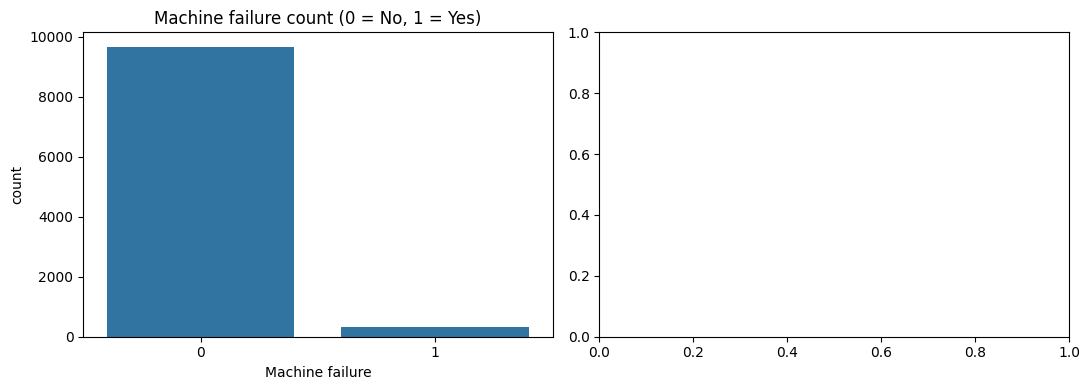

In [42]:
print(df["Machine failure"].value_counts())
print()
print(df["Machine failure"].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Machine failure", data=df, ax=ax[0])
ax[0].set_title("Machine failure count (0 = No, 1 = Yes)")


plt.tight_layout()
plt.show()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


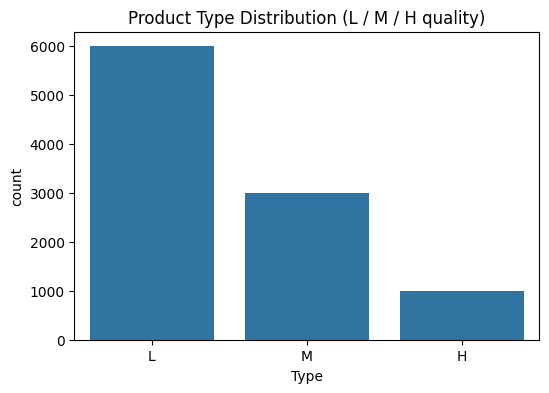

In [43]:
print(df["Type"].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(x="Type", data=df, order=["L", "M", "H"])
plt.title("Product Type Distribution (L / M / H quality)")
plt.show()

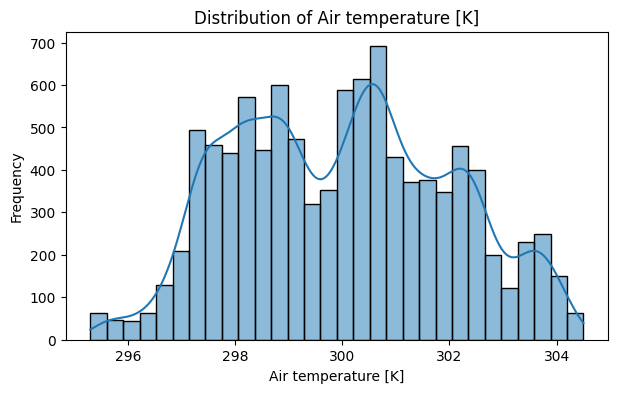

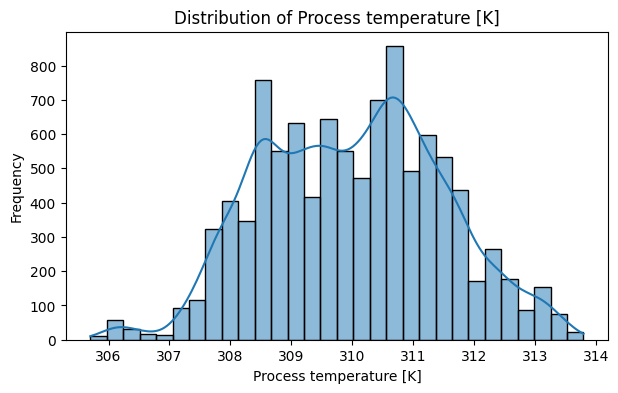

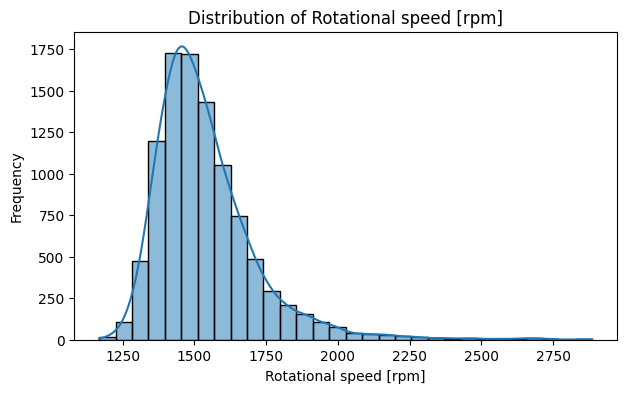

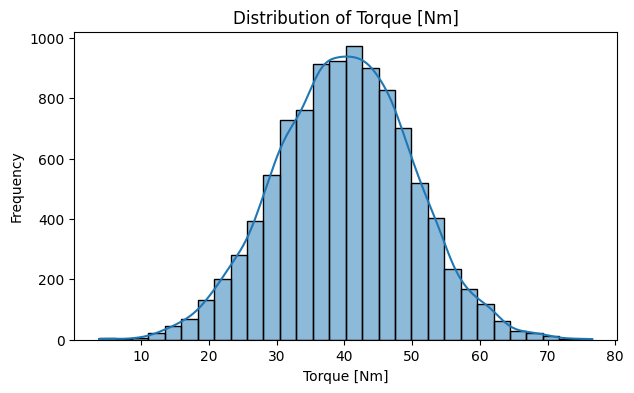

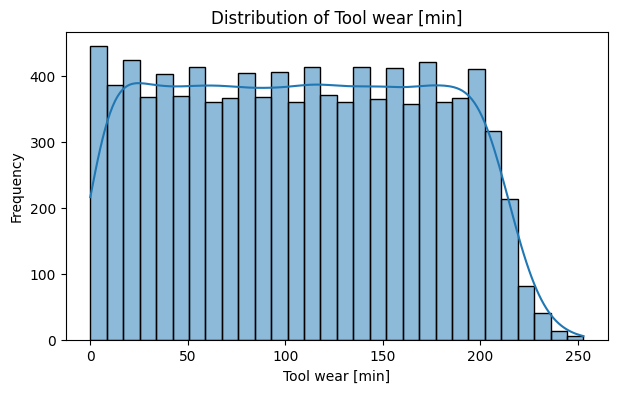

In [44]:
numerical_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
                      "Torque [Nm]", "Tool wear [min]"]

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

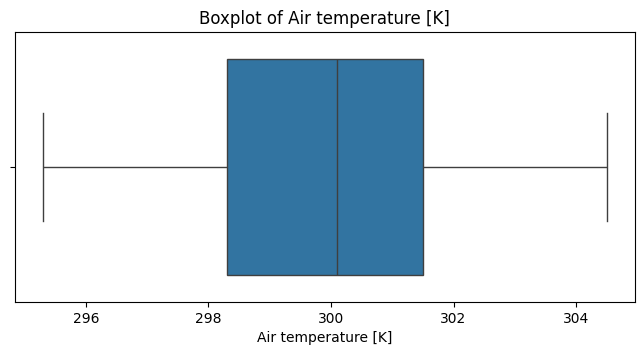

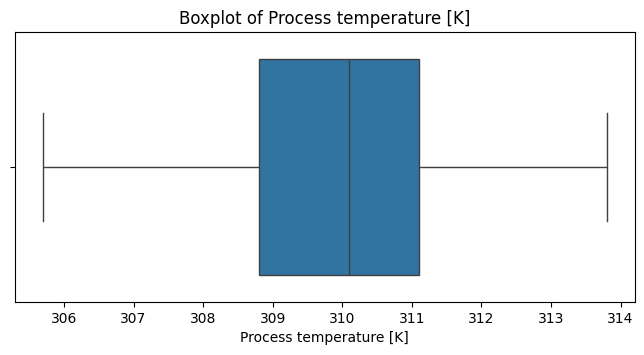

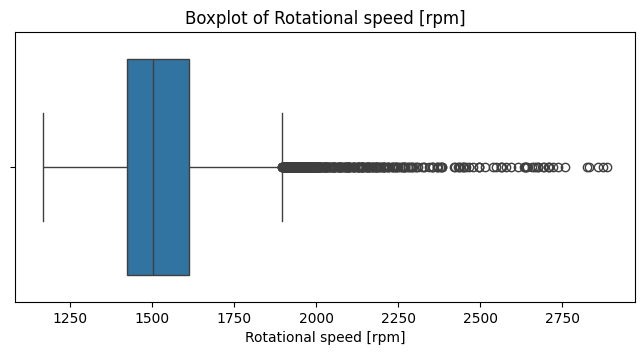

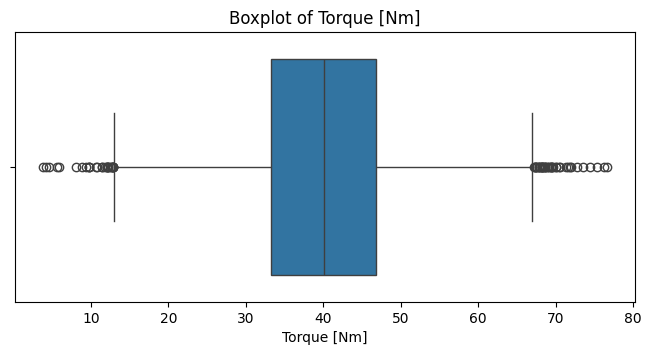

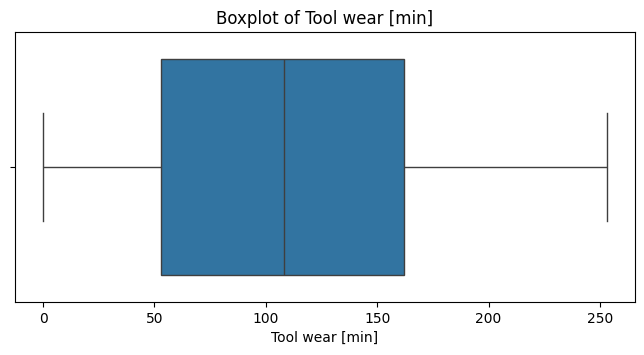

In [45]:
for col in numerical_features:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [46]:
num_df = df[numerical_features]

Q1 = num_df.quantile(0.25)
Q3 = num_df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (num_df < lower_bound) | (num_df > upper_bound)
outlier_count = outlier_mask.sum()
outlier_percentage = (outlier_count / len(num_df)) * 100

outlier_summary = pd.DataFrame({
    "Q1": Q1, "Q3": Q3, "IQR": IQR,
    "lower bound": lower_bound, "upper bound": upper_bound,
    "Outlier Count": outlier_count, "Outlier %": outlier_percentage
})
outlier_summary.round(3)

,Q1,Q3,IQR,lower bound,upper bound,Outlier Count,Outlier %
Air temperature [K],298.3,301.5,3.2,293.50,306.30,0,0.00
Process temperature [K],308.8,311.1,2.3,305.35,314.55,0,0.00
Rotational speed [rpm],1423.0,1612.0,189.0,1139.50,1895.50,418,4.18
Torque [Nm],33.2,46.8,13.6,12.80,67.20,69,0.69
Tool wear [min],53.0,162.0,109.0,-110.50,325.50,0,0.00


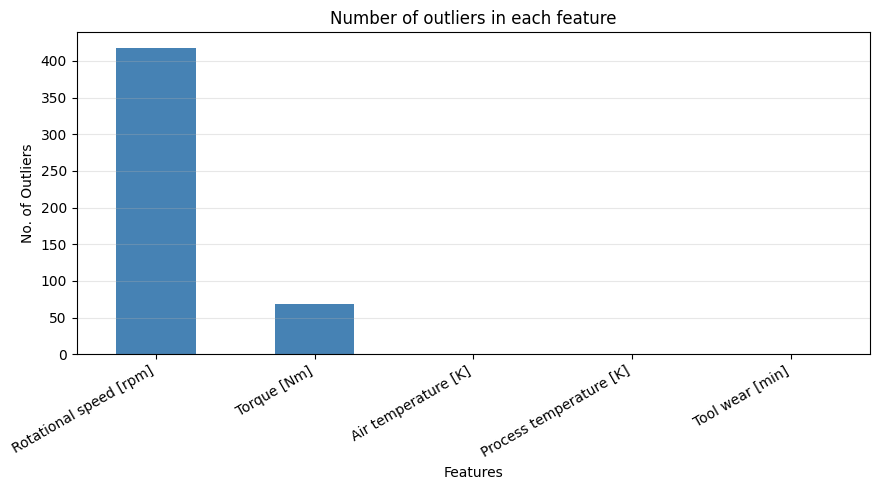

In [47]:
plt.figure(figsize=(9, 5))
outlier_count.sort_values(ascending=False).plot(kind="bar", color="steelblue")
plt.title("Number of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No. of Outliers")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


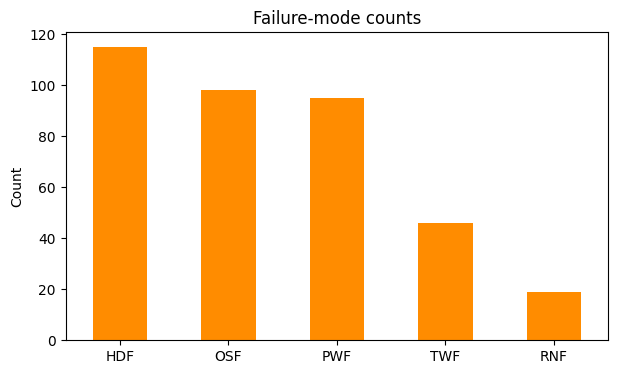

In [48]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_counts = df[failure_modes].sum().sort_values(ascending=False)
print(mode_counts)

plt.figure(figsize=(7, 4))
mode_counts.plot(kind="bar", color="darkorange")
plt.title("Failure-mode counts")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

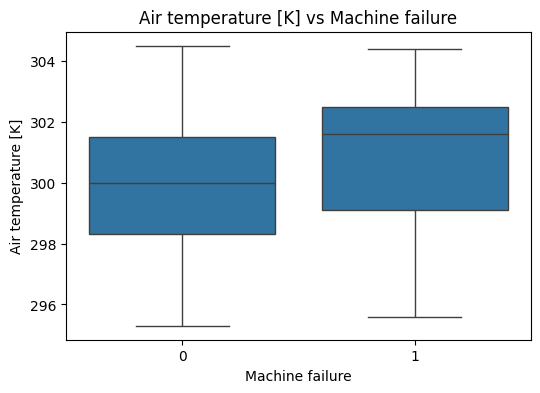

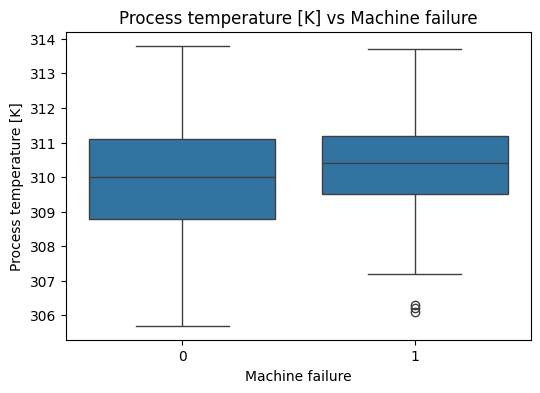

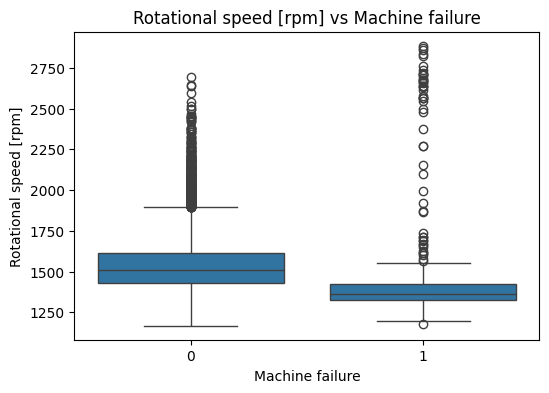

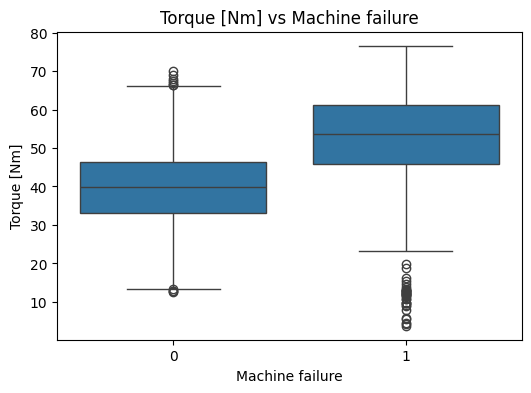

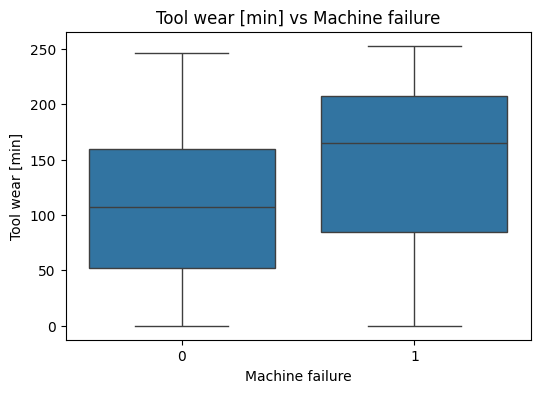

In [49]:
for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x="Machine failure", y=col, data=df)
    plt.title(f"{col} vs Machine failure")
    plt.show()

Type
L    3.92
M    2.77
H    2.09
Name: Machine failure, dtype: float64


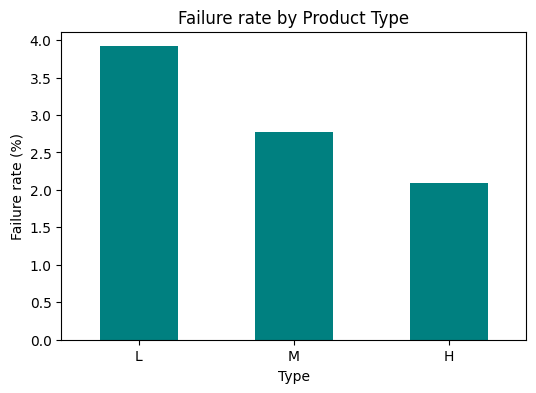

In [50]:
type_rate = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"]) * 100
print(type_rate.round(2))

plt.figure(figsize=(6, 4))
type_rate.plot(kind="bar", color="teal")
plt.ylabel("Failure rate (%)")
plt.title("Failure rate by Product Type")
plt.xticks(rotation=0)
plt.show()

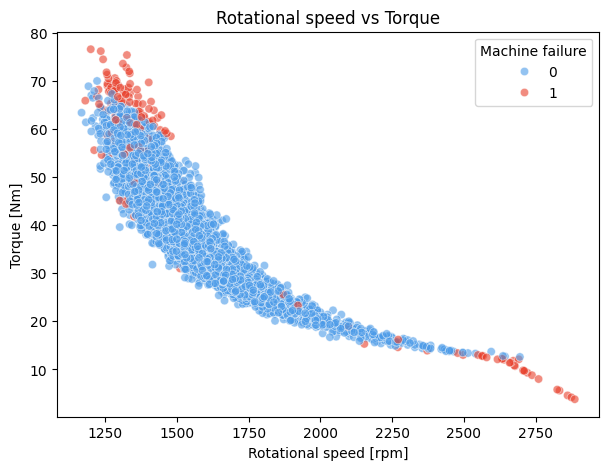

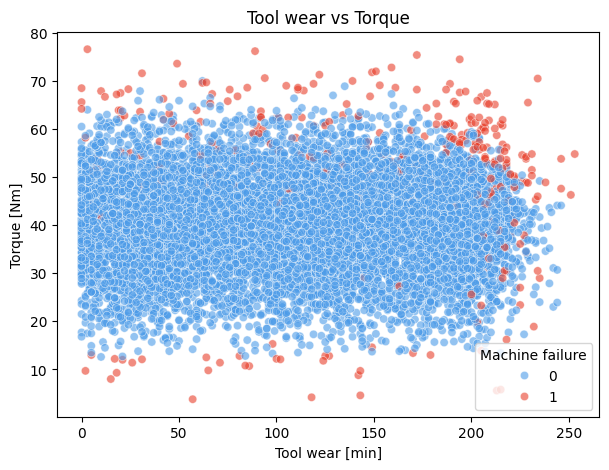

In [51]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="Rotational speed [rpm]", y="Torque [Nm]", hue="Machine failure",
                data=df, alpha=0.6, palette={0: "#4C9BE8", 1: "#E8402C"})
plt.title("Rotational speed vs Torque")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x="Tool wear [min]", y="Torque [Nm]", hue="Machine failure",
                data=df, alpha=0.6, palette={0: "#4C9BE8", 1: "#E8402C"})
plt.title("Tool wear vs Torque")
plt.show()

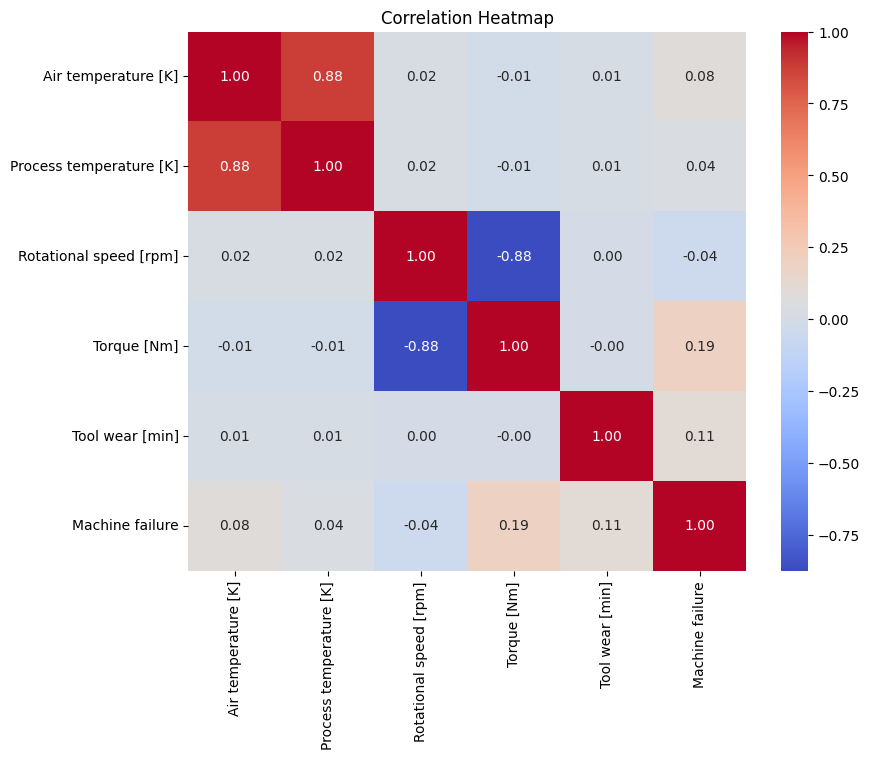

In [52]:
plt.figure(figsize=(9, 7))
corr_cols = numerical_features + ["Machine failure"]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

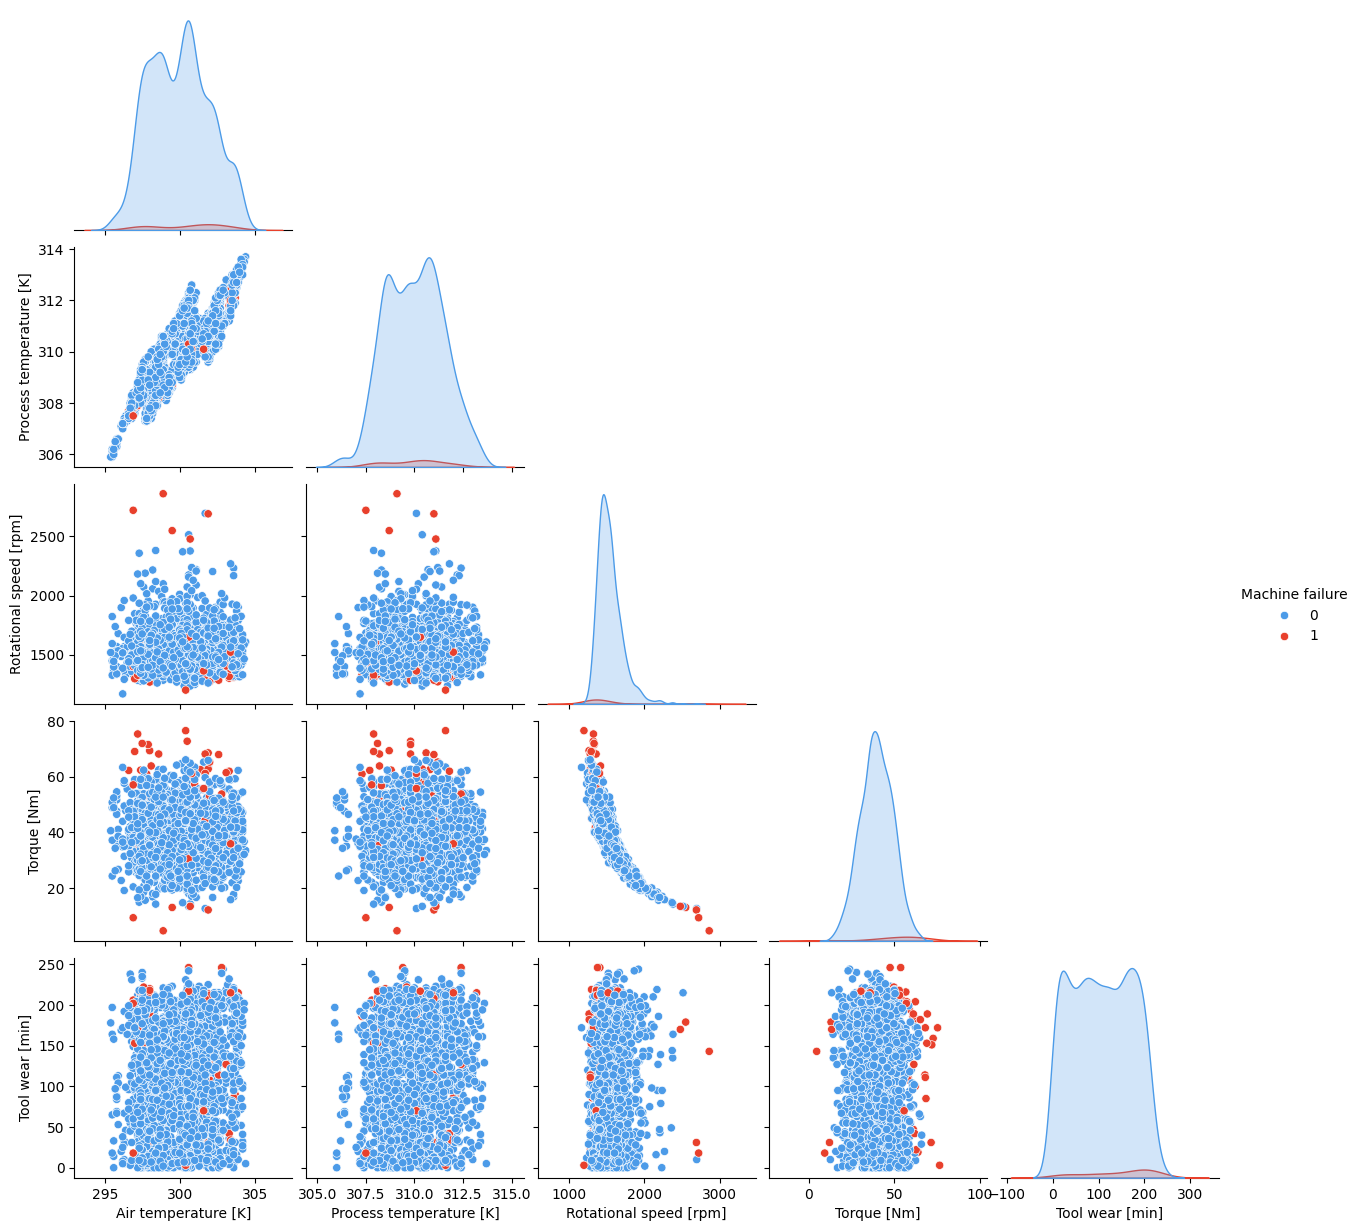

In [53]:
sns.pairplot(df[numerical_features + ["Machine failure"]].sample(2000, random_state=42),
             hue="Machine failure", diag_kind="kde", corner=True,
             palette={0: "#4C9BE8", 1: "#E8402C"})
plt.show()

In [13]:
X=df.drop("Machine failure",axis=1)
y=df["Machine failure"]

In [14]:
print(X.shape)
print(y.shape)

(10000, 13)
(10000,)


In [15]:
categorical_features=["Type"]

numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [16]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [20]:
linear_svm=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="linear"))]
)
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [21]:
y_pred_linear=linear_svm.predict(X_test)

In [22]:
accuracy_linear=accuracy_score(y_test,y_pred_linear)

precision_linear=precision_score(y_test,y_pred_linear,zero_division=0)

recall_linear=recall_score(y_test,y_pred_linear,zero_division=0)

f1_linear=f1_score(y_test,y_pred_linear,zero_division=0)

print("Accuracy:",accuracy_linear)
print("Precision:",precision_linear)
print("Recall:",recall_linear)
print("F1 Score:",f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [23]:
print(classification_report(y_test,y_pred_linear,target_names=["No Failure","Failure"],zero_division=0)
     )

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



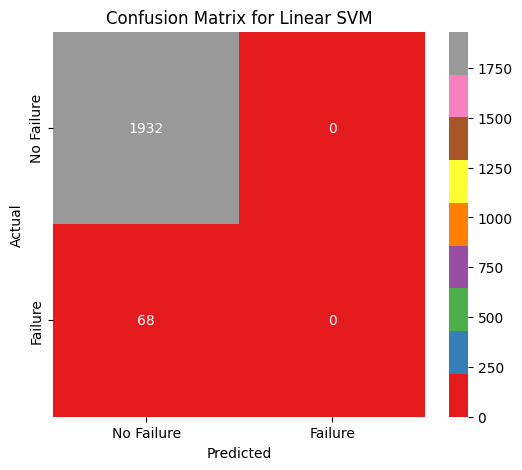

In [24]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Set1",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Linear SVM")
plt.show()

In [26]:
rbf_svm=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="rbf"))]
)
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [27]:
y_pred_rbf=rbf_svm.predict(X_test)

In [28]:
print(classification_report(y_test,y_pred_rbf,target_names=["No Failure","Failure"],zero_division=0)
     )

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



In [29]:
accuracy_rbf=accuracy_score(y_test,y_pred_rbf)

precision_rbf=precision_score(y_test,y_pred_rbf,zero_division=0)

recall_rbf=recall_score(y_test,y_pred_rbf,zero_division=0)

f1_rbf=f1_score(y_test,y_pred_rbf,zero_division=0)

print("Accuracy:",accuracy_linear)
print("Precision:",precision_linear)
print("Recall:",recall_rbf)
print("F1 Score:",f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.20588235294117646
F1 Score: 0.0


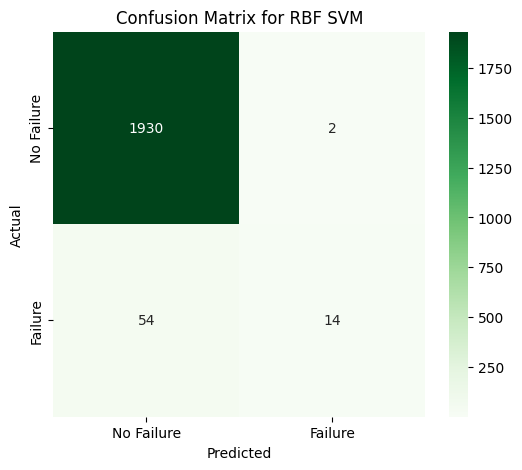

In [30]:
cm_rbf=confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="Greens",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for RBF SVM")
plt.show()

In [31]:
comparison = pd.DataFrame({
    "Kernel": ["Linear", "RBF"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 Score": [f1_linear, f1_rbf]
})

comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.966,0.000,0.000000,0.000000
1,RBF,0.972,0.875,0.205882,0.333333


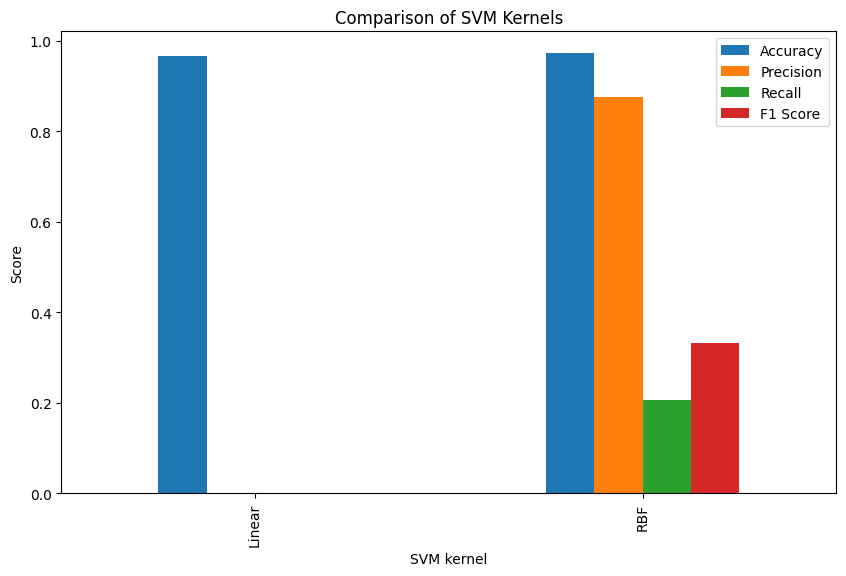

In [32]:
comparision_plot=comparison.set_index("Kernel")
comparision_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM kernel")
plt.ylabel("Score")
plt.show()

In [35]:
from sklearn.pipeline import Pipeline
pipeline=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC())]
)

In [36]:
param_grid=[{"classifier_kernel":["linear"],"classifier_C":[0.1,1,10,100]},
             {"classifier_kernel":["rbf"],"classifier_C":[0.1,1,10,100],"classifier_gamma":["scale",0.01,0.1,1]}]

In [37]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=1,
    verbose=1
)

In [38]:
param_grid = {
    "classifier__C": [1, 10],
    "classifier__kernel": ["linear", "rbf"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=2,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


GridSearchCV(cv=3, error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('classifier', SVC())]),
             n_jobs=-1,
             param_grid={'classifier__C': [1, 10],
                         'classifier__kernel': ['linear', 'rbf']},
             scoring='f1', verbose=2)

In [39]:
print("GridSearch CV Complete")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation F1 Score:", grid_search.best_score_)

GridSearch CV Complete
Best Parameters: {'classifier__C': 10, 'classifier__kernel': 'rbf'}
Best Cross Validation F1 Score: 0.6324307656407564


In [40]:
y_pred_tuned = grid_search.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

In [41]:
final_comaprision = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision_tuned],
    "Recall": [recall_linear, recall_rbf, recall_tuned],
    "F1 Score": [f1_linear, f1_rbf, f1_tuned]
})

print(final_comaprision)

        Model  Accuracy  Precision    Recall  F1 Score
0  Linear SVM     0.966   0.000000  0.000000  0.000000
1     RBF SVM     0.972   0.875000  0.205882  0.333333
2   Tuned SVM     0.979   0.770833  0.544118  0.637931
